## Import All the Libraries:-

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#remove Warnings
import warnings
warnings.filterwarnings('ignore')

## Upload the DataFrame

In [2]:
# read and upload the dataset
df= pd.read_csv("Airbnb_Open_Data.csv")
df

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,country,...,service fee,minimum nights,number of reviews,last review,reviews per month,review rate number,calculated host listings count,availability 365,house_rules,license
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,United States,...,$193,10.0,9.0,10/19/2021,0.21,4.0,6.0,286.0,Clean up and treat the home the way you'd like...,NaN
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,United States,...,$28,30.0,45.0,5/21/2022,0.38,4.0,2.0,228.0,Pet friendly but please confirm with me if the...,NaN
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,United States,...,$124,3.0,0.0,NaN,NaN,5.0,1.0,352.0,"I encourage you to use my kitchen, cooking and...",NaN
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,United States,...,$74,30.0,270.0,7/5/2019,4.64,4.0,1.0,322.0,NaN,NaN
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,United States,...,$41,10.0,9.0,11/19/2018,0.10,3.0,1.0,289.0,"Please no smoking in the house, porch or on th...",NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,United States,...,$169,1.0,0.0,NaN,NaN,3.0,1.0,227.0,No Smoking No Parties or Events of any kind Pl...,NaN
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,United States,...,$167,1.0,1.0,7/6/2015,0.02,2.0,2.0,395.0,House rules: Guests agree to the following ter...,NaN
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,United States,...,$198,3.0,0.0,NaN,NaN,5.0,1.0,342.0,NaN,NaN
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,United States,...,$109,2.0,5.0,10/11/2015,0.10,3.0,1.0,386.0,NaN,NaN


## Dataset Description:- 
    - Airbnb, Inc is an American company that operates an online marketplace for lodging, primarily homestays for vacation rentals, and tourism activities. Based in San Francisco, California, the platform is accessible via website and mobile app. Airbnb does not own any of the listed properties; instead, it profits by receiving commission from each booking. The company was founded in 2008. Airbnb is a shortened version of its original name, AirBedandBreakfast.com.
    
    - The Airbnb dataset contains information about Airbnb listings in New York City. It includes details about hosts, property locations, room types, prices, minimum stay requirements, reviews, and availability. The dataset is useful for practicing data cleaning and preprocessing techniques such as handling missing values, duplicates, inconsistent data, incorrect data types, and outliers.

## EDA Cleaning Process:- 

In [3]:
 # Let's Check out the Columns
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'country',
       'country code', 'instant_bookable', 'cancellation_policy', 'room type',
       'Construction year', 'price', 'service fee', 'minimum nights',
       'number of reviews', 'last review', 'reviews per month',
       'review rate number', 'calculated host listings count',
       'availability 365', 'house_rules', 'license'],
      dtype='object')

In [4]:
# it return (number of rows, number of columns)
df.shape

(102599, 26)

In [5]:
''' In pandas, df.info() is a built-in method used to get a 
concise summary of a DataFrame. It is one of the most common commands used during the initial data exploration phase.'''
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102599 entries, 0 to 102598
Data columns (total 26 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   id                              102599 non-null  int64  
 1   NAME                            102349 non-null  object 
 2   host id                         102599 non-null  int64  
 3   host_identity_verified          102310 non-null  object 
 4   host name                       102193 non-null  object 
 5   neighbourhood group             102570 non-null  object 
 6   neighbourhood                   102583 non-null  object 
 7   lat                             102591 non-null  float64
 8   long                            102591 non-null  float64
 9   country                         102067 non-null  object 
 10  country code                    102468 non-null  object 
 11  instant_bookable                102494 non-null  object 
 12  cancellation_pol

In [6]:
# Delete unnecessary columns data
df= df.drop(columns =['review rate number','house_rules','license',
                      'country','country code','instant_bookable',
                      'cancellation_policy','Construction year'])

In [7]:
df.columns

Index(['id', 'NAME', 'host id', 'host_identity_verified', 'host name',
       'neighbourhood group', 'neighbourhood', 'lat', 'long', 'room type',
       'price', 'service fee', 'minimum nights', 'number of reviews',
       'last review', 'reviews per month', 'calculated host listings count',
       'availability 365'],
      dtype='object')

In [8]:
df.shape

(102599, 18)

## Columns Description:- 

In [9]:
'''
id	:-              Unique identification number assigned to each Airbnb listing
name :-          	Name/title of the Airbnb listing
host_id :-          Unique identification number of the host
host_identity_verified :- It indicates whether the host has completed Airbnb official identity verification process
host_name:-     	      Name of the host
neighbourhood_group :-    NYC(New York City) area where the listing is located.
neighbourhood :- 	      Specific neighborhood where the listing is located
latitude :- 	          Geographic latitude of the Airbnb listing
longitude :-              Geographic longitude of the Airbnb listing
room_type :- 	          Type of accommodation
price :- 	              Price charged for the listing per night
service fee :- 
minimum_nights :- 	      Minimum number of nights a guest must book
number_of_reviews :-      Total number of reviews received by the listing
last_review :-            when the listing received its most recent review
reviews_per_month :-	  Average number of reviews received per month
calculated_host_listings_count :- 	Number of listings managed by the same host
availability_365 :-             	Number of days the listing is available for booking during a year
'''

'\nid\t:-              Unique identification number assigned to each Airbnb listing\nname :-          \tName/title of the Airbnb listing\nhost_id :-          Unique identification number of the host\nhost_identity_verified :- It indicates whether the host has completed Airbnb official identity verification process\nhost_name:-     \t      Name of the host\nneighbourhood_group :-    NYC(New York City) area where the listing is located.\nneighbourhood :- \t      Specific neighborhood where the listing is located\nlatitude :- \t          Geographic latitude of the Airbnb listing\nlongitude :-              Geographic longitude of the Airbnb listing\nroom_type :- \t          Type of accommodation\nprice :- \t              Price charged for the listing per night\nservice fee :- \nminimum_nights :- \t      Minimum number of nights a guest must book\nnumber_of_reviews :-      Total number of reviews received by the listing\nlast_review :-            when the listing received its most recent re

In [10]:
#shows top 5 rows by default
df.head()

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,room type,price,service fee,minimum nights,number of reviews,last review,reviews per month,calculated host listings count,availability 365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,$966,$193,10.0,9.0,10/19/2021,0.21,6.0,286.0
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,$142,$28,30.0,45.0,5/21/2022,0.38,2.0,228.0
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,$620,$124,3.0,0.0,NaN,NaN,1.0,352.0
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,$368,$74,30.0,270.0,7/5/2019,4.64,1.0,322.0
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,$204,$41,10.0,9.0,11/19/2018,0.10,1.0,289.0


In [11]:
#shows bottom 5 rows by default
df.tail()

,id,NAME,host id,host_identity_verified,host name,neighbourhood group,neighbourhood,lat,long,room type,price,service fee,minimum nights,number of reviews,last review,reviews per month,calculated host listings count,availability 365
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,Private room,$844,$169,1.0,0.0,NaN,NaN,1.0,227.0
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,Private room,$837,$167,1.0,1.0,7/6/2015,0.02,2.0,395.0
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,Private room,$988,$198,3.0,0.0,NaN,NaN,1.0,342.0
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,Entire home/apt,$546,$109,2.0,5.0,10/11/2015,0.10,1.0,386.0
102598,6094647,585 sf Luxury Studio,68170633372,unconfirmed,Rebecca,Manhattan,Upper West Side,40.76807,-73.98342,Entire home/apt,"$1,032",$206,1.0,0.0,NaN,NaN,1.0,69.0


In [12]:
# it gives statistical summary for numerical columns:-
df.describe()

,id,host id,lat,long,minimum nights,number of reviews,reviews per month,calculated host listings count,availability 365
count,1.025990e+05,1.025990e+05,102591.000000,102591.000000,102190.000000,102416.000000,86720.000000,102280.000000,102151.000000
mean,2.914623e+07,4.925411e+10,40.728094,-73.949644,8.135845,27.483743,1.374022,7.936605,141.133254
std,1.625751e+07,2.853900e+10,0.055857,0.049521,30.553781,49.508954,1.746621,32.218780,135.435024
min,1.001254e+06,1.236005e+08,40.499790,-74.249840,-1223.000000,0.000000,0.010000,1.000000,-10.000000
25%,1.508581e+07,2.458333e+10,40.688740,-73.982580,2.000000,1.000000,0.220000,1.000000,3.000000
50%,2.913660e+07,4.911774e+10,40.722290,-73.954440,3.000000,7.000000,0.740000,1.000000,96.000000
75%,4.320120e+07,7.399650e+10,40.762760,-73.932350,5.000000,30.000000,2.000000,2.000000,269.000000
max,5.736742e+07,9.876313e+10,40.916970,-73.705220,5645.000000,1024.000000,90.000000,332.000000,3677.000000


## Columns Alterning 

In [13]:
df = df.rename(columns = {
    "id" : "ID",
    "NAME" : "Name",
    "host id" : "Host_ID",
    "host_identity_verified" : "Host_Identity_Verified",
    "host name" : "Host_Name",
    "neighbourhood group" : "Neighbourhood_Group",
    "neighbourhood" : "Neighbourhood",
    "lat" : "Latitude",
    "long" : "Longitude",
    "room type" : "Room_Type",
    "price" : "Price($)",
    "service fee" : "Service_Fees($)",
    "minimum nights" : "Minimum_Nights",
    "number of reviews" : "Number_of_Reviews",
    "last review" : "Last_Review",
    "reviews per month":"Reviews_Per_Month",
    "last review" : "Last_Review",
    "reviews per month" : "Reviews_Per_Month",
    "calculated host listings count" : "Calculated_Host_Listings_Count",
    "availability 365" : "Availability_365"
})

In [14]:
df.columns

Index(['ID', 'Name', 'Host_ID', 'Host_Identity_Verified', 'Host_Name',
       'Neighbourhood_Group', 'Neighbourhood', 'Latitude', 'Longitude',
       'Room_Type', 'Price($)', 'Service_Fees($)', 'Minimum_Nights',
       'Number_of_Reviews', 'Last_Review', 'Reviews_Per_Month',
       'Calculated_Host_Listings_Count', 'Availability_365'],
      dtype='object')

## Null Value Counting

In [15]:
#finding total count of null values in a dataset
df.isnull().sum()

ID                                    0
Name                                250
Host_ID                               0
Host_Identity_Verified              289
Host_Name                           406
Neighbourhood_Group                  29
Neighbourhood                        16
Latitude                              8
Longitude                             8
Room_Type                             0
Price($)                            247
Service_Fees($)                     273
Minimum_Nights                      409
Number_of_Reviews                   183
Last_Review                       15893
Reviews_Per_Month                 15879
Calculated_Host_Listings_Count      319
Availability_365                    448
dtype: int64

In [16]:
# Missing values in Percentage
missing_percentage= (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values()

ID                                 0.000000
Room_Type                          0.000000
Host_ID                            0.000000
Latitude                           0.007797
Longitude                          0.007797
Neighbourhood                      0.015595
Neighbourhood_Group                0.028265
Number_of_Reviews                  0.178364
Price($)                           0.240743
Name                               0.243667
Service_Fees($)                    0.266084
Host_Identity_Verified             0.281679
Calculated_Host_Listings_Count     0.310919
Host_Name                          0.395715
Minimum_Nights                     0.398639
Availability_365                   0.436651
Reviews_Per_Month                 15.476759
Last_Review                       15.490404
dtype: float64

## Checking Unique and Duplicate values and Drop Duplicates Values

In [17]:
# to check the unique values
print(df['ID'].is_unique)
print(df['ID'].duplicated().sum())

False
541


In [18]:
# to check the unique values
print(df['Host_ID'].is_unique)
print(df['Host_ID'].duplicated().sum())

False
542


In [19]:
df[df.duplicated()]

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
102058,35506831,Master Bedroom with private Bathroom & Balcony,55110690425,unconfirmed,UZeyir,Queens,Maspeth,40.74056,-73.90635,Private room,$706,$141,1.0,1.0,11/14/2021,0.27,1.0,339.0
102059,35507383,Cozy 2 br in sunny Fort Greene apt,80193772189,verified,Sally,Brooklyn,Fort Greene,40.68701,-73.97555,Private room,$651,$130,3.0,38.0,11/13/2021,0.27,1.0,0.0
102060,35507935,Duplex w/ Terrace @ Box House Hotel,72991962259,verified,The Box House Hotel,Brooklyn,Greenpoint,40.73756,-73.95350,Hotel room,$907,$181,3.0,10.0,11/13/2021,0.08,30.0,32.0
102061,35508488,"Cozy, clean Greenpoint room with yard access",74975156081,verified,Dawn,Brooklyn,Greenpoint,40.72516,-73.95004,Private room,$589,$118,30.0,38.0,11/13/2021,0.34,2.0,324.0
102062,35509040,2BR XL Loft: Cleaning CDC guidelines implemented,85844415221,unconfirmed,Vida,Brooklyn,Greenpoint,40.72732,-73.94185,Entire home/apt,$356,$71,30.0,13.0,11/13/2021,0.14,28.0,336.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102594,6092437,Spare room in Williamsburg,12312296767,verified,Krik,Brooklyn,Williamsburg,40.70862,-73.94651,Private room,$844,$169,1.0,0.0,NaN,NaN,1.0,227.0
102595,6092990,Best Location near Columbia U,77864383453,unconfirmed,Mifan,Manhattan,Morningside Heights,40.80460,-73.96545,Private room,$837,$167,1.0,1.0,7/6/2015,0.02,2.0,395.0
102596,6093542,"Comfy, bright room in Brooklyn",69050334417,unconfirmed,Megan,Brooklyn,Park Slope,40.67505,-73.98045,Private room,$988,$198,3.0,0.0,NaN,NaN,1.0,342.0
102597,6094094,Big Studio-One Stop from Midtown,11160591270,unconfirmed,Christopher,Queens,Long Island City,40.74989,-73.93777,Entire home/apt,$546,$109,2.0,5.0,10/11/2015,0.10,1.0,386.0


In [20]:
# duplicate records 
duplicate_ids = df[df.duplicated("ID", keep=False)].sort_values("ID")
duplicate_ids.head(4)

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
9098,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.96030,Entire home/apt,$105,$21,30.0,2.0,6/8/2019,0.21,34.0,157.0
102474,6026161,Upper East Side 2 bedroom- close to Hospitals-,65193709566,verified,Juliana,Manhattan,Upper East Side,40.76222,-73.96030,Entire home/apt,$105,$21,30.0,2.0,6/8/2019,0.21,34.0,157.0
102475,6026714,Close to East Side Hospitals- Modern 2 Bedroom...,31072202372,verified,Juliana,Manhattan,Upper East Side,40.76249,-73.96217,Entire home/apt,$285,$57,30.0,6.0,1/31/2019,0.14,34.0,67.0
9099,6026714,Close to East Side Hospitals- Modern 2 Bedroom...,31072202372,verified,Juliana,Manhattan,Upper East Side,40.76249,-73.96217,Entire home/apt,$285,$57,30.0,6.0,1/31/2019,0.14,34.0,67.0


In [21]:
# Drop all the Duplicate IDs
df.drop_duplicates(inplace=True)

In [22]:
# to check the unique values in ID Column
print(df['ID'].is_unique)
print(df['ID'].duplicated().sum())

True
0


In [23]:
# to check the unique values in Host_ID column :-
print(df['Host_ID'].is_unique)
print(df['Host_ID'].duplicated().sum())

False
1


In [24]:
# note :- 1 Host ID record is same but main ID is Different that's why 1 record was not removed.
duplicate_host_ids = df[df.duplicated("Host_ID", keep=False)]
duplicate_host_ids

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
23397,13923499,Magnificent Lakeview Home on Kissena Park in NYC,29531702698,verified,Ann,Queens,Flushing,40.74982,-73.80610,Entire home/apt,"$1,042",$208,3.0,0.0,NaN,NaN,6.0,256.0
42960,24728144,NaN,29531702698,verified,Seth,Brooklyn,Williamsburg,40.71867,-73.96163,Private room,"$1,142",$228,2.0,1.0,5/19/2019,0.59,1.0,44.0


In [25]:
''' 
# note :- 
- After exact duplicate removal, one Host_ID remained repeated because the same host can manage different listings.
- One host can have multiple Airbnb listings, so the same Host_ID can appear with different IDs.
- So do NOT delete these rows just because Host_ID is repeated.
'''

' \n# note :- \n- After exact duplicate removal, one Host_ID remained repeated because the same host can manage different listings.\n- One host can have multiple Airbnb listings, so the same Host_ID can appear with different IDs.\n- So do NOT delete these rows just because Host_ID is repeated.\n'

## Now check and fill Missing Values

In [26]:
df.isnull().sum()

ID                                    0
Name                                250
Host_ID                               0
Host_Identity_Verified              289
Host_Name                           404
Neighbourhood_Group                  29
Neighbourhood                        16
Latitude                              8
Longitude                             8
Room_Type                             0
Price($)                            247
Service_Fees($)                     273
Minimum_Nights                      400
Number_of_Reviews                   183
Last_Review                       15832
Reviews_Per_Month                 15818
Calculated_Host_Listings_Count      319
Availability_365                    448
dtype: int64

In [27]:
# checking missing value in percentage
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_percentage.sort_values(ascending=False)

Last_Review                       15.512748
Reviews_Per_Month                 15.499030
Availability_365                   0.438966
Host_Name                          0.395853
Minimum_Nights                     0.391934
Calculated_Host_Listings_Count     0.312567
Host_Identity_Verified             0.283172
Service_Fees($)                    0.267495
Name                               0.244959
Price($)                           0.242019
Number_of_Reviews                  0.179310
Neighbourhood_Group                0.028415
Neighbourhood                      0.015677
Latitude                           0.007839
Longitude                          0.007839
ID                                 0.000000
Host_ID                            0.000000
Room_Type                          0.000000
dtype: float64

In [28]:
# Create New Data Frame using copy() method.
new_data_frame_to_clean = df.copy()

In [29]:
new_data_frame_to_clean

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,$966,$193,10.0,9.0,10/19/2021,0.21,6.0,286.0
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,$142,$28,30.0,45.0,5/21/2022,0.38,2.0,228.0
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,$620,$124,3.0,0.0,NaN,NaN,1.0,352.0
3,1002755,NaN,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,$368,$74,30.0,270.0,7/5/2019,4.64,1.0,322.0
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,$204,$41,10.0,9.0,11/19/2018,0.10,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102053,57365208,Cozy bright room near Prospect Park,77326652202,unconfirmed,Mariam,Brooklyn,Flatbush,40.64945,-73.96108,Private room,$696,NaN,7.0,12.0,3/27/2019,0.44,1.0,0.0
102054,57365760,Private Bedroom with Amazing Rooftop View,45936254757,verified,Trey,Brooklyn,Bushwick,40.69872,-73.92718,Private room,$909,NaN,1.0,19.0,8/31/2017,0.72,2.0,0.0
102055,57366313,Pretty Brooklyn One-Bedroom for 2 to 4 people,23801060917,verified,Michael,Brooklyn,Bedford-Stuyvesant,40.67810,-73.90822,Entire home/apt,$387,NaN,2.0,50.0,6/26/2019,3.12,2.0,235.0
102056,57366865,Room & private bathroom in historic Harlem,15593031571,unconfirmed,Shireen,Manhattan,Harlem,40.81248,-73.94317,Private room,$848,NaN,2.0,0.0,NaN,NaN,1.0,0.0


In [30]:
new_data_frame_to_clean.isnull().sum()

ID                                    0
Name                                250
Host_ID                               0
Host_Identity_Verified              289
Host_Name                           404
Neighbourhood_Group                  29
Neighbourhood                        16
Latitude                              8
Longitude                             8
Room_Type                             0
Price($)                            247
Service_Fees($)                     273
Minimum_Nights                      400
Number_of_Reviews                   183
Last_Review                       15832
Reviews_Per_Month                 15818
Calculated_Host_Listings_Count      319
Availability_365                    448
dtype: int64

In [31]:
'''1) First Clean the Name column:-
null value replace to 'unknown' because the listing still contains other 
useful information such as price, location, room type, reviews, etc. '''
new_data_frame_to_clean["Name"] = new_data_frame_to_clean["Name"].fillna("Unknown")
new_data_frame_to_clean

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,$966,$193,10.0,9.0,10/19/2021,0.21,6.0,286.0
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,$142,$28,30.0,45.0,5/21/2022,0.38,2.0,228.0
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,$620,$124,3.0,0.0,NaN,NaN,1.0,352.0
3,1002755,Unknown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,$368,$74,30.0,270.0,7/5/2019,4.64,1.0,322.0
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,$204,$41,10.0,9.0,11/19/2018,0.10,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102053,57365208,Cozy bright room near Prospect Park,77326652202,unconfirmed,Mariam,Brooklyn,Flatbush,40.64945,-73.96108,Private room,$696,NaN,7.0,12.0,3/27/2019,0.44,1.0,0.0
102054,57365760,Private Bedroom with Amazing Rooftop View,45936254757,verified,Trey,Brooklyn,Bushwick,40.69872,-73.92718,Private room,$909,NaN,1.0,19.0,8/31/2017,0.72,2.0,0.0
102055,57366313,Pretty Brooklyn One-Bedroom for 2 to 4 people,23801060917,verified,Michael,Brooklyn,Bedford-Stuyvesant,40.67810,-73.90822,Entire home/apt,$387,NaN,2.0,50.0,6/26/2019,3.12,2.0,235.0
102056,57366865,Room & private bathroom in historic Harlem,15593031571,unconfirmed,Shireen,Manhattan,Harlem,40.81248,-73.94317,Private room,$848,NaN,2.0,0.0,NaN,NaN,1.0,0.0


In [32]:
# 3) Host Name Column Cleaning
new_data_frame_to_clean["Host_Name"] = new_data_frame_to_clean["Host_Name"].fillna("UNKNOWN")
new_data_frame_to_clean

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,$966,$193,10.0,9.0,10/19/2021,0.21,6.0,286.0
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,$142,$28,30.0,45.0,5/21/2022,0.38,2.0,228.0
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,NaN,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,$620,$124,3.0,0.0,NaN,NaN,1.0,352.0
3,1002755,Unknown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,$368,$74,30.0,270.0,7/5/2019,4.64,1.0,322.0
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,$204,$41,10.0,9.0,11/19/2018,0.10,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102053,57365208,Cozy bright room near Prospect Park,77326652202,unconfirmed,Mariam,Brooklyn,Flatbush,40.64945,-73.96108,Private room,$696,NaN,7.0,12.0,3/27/2019,0.44,1.0,0.0
102054,57365760,Private Bedroom with Amazing Rooftop View,45936254757,verified,Trey,Brooklyn,Bushwick,40.69872,-73.92718,Private room,$909,NaN,1.0,19.0,8/31/2017,0.72,2.0,0.0
102055,57366313,Pretty Brooklyn One-Bedroom for 2 to 4 people,23801060917,verified,Michael,Brooklyn,Bedford-Stuyvesant,40.67810,-73.90822,Entire home/apt,$387,NaN,2.0,50.0,6/26/2019,3.12,2.0,235.0
102056,57366865,Room & private bathroom in historic Harlem,15593031571,unconfirmed,Shireen,Manhattan,Harlem,40.81248,-73.94317,Private room,$848,NaN,2.0,0.0,NaN,NaN,1.0,0.0


In [33]:
#now check the Name column["Name"]
new_data_frame_to_clean["Name"].isnull().sum()

np.int64(0)

In [34]:
#now check the Host Name column["Host_Name"]
new_data_frame_to_clean["Host_Name"].isnull().sum()

np.int64(0)

In [35]:
# 2) cleaning Host_Identity_Verified column
new_data_frame_to_clean["Host_Identity_Verified"].value_counts()

Host_Identity_Verified
unconfirmed    50944
verified       50825
Name: count, dtype: int64

In [36]:
new_data_frame_to_clean["Host_Identity_Verified"].isnull().sum()

np.int64(289)

In [37]:
# fill null value to Unverified because actual verification status was unavailable.
new_data_frame_to_clean["Host_Identity_Verified"] = new_data_frame_to_clean["Host_Identity_Verified"].fillna("unverified")
new_data_frame_to_clean

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,$966,$193,10.0,9.0,10/19/2021,0.21,6.0,286.0
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,$142,$28,30.0,45.0,5/21/2022,0.38,2.0,228.0
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unverified,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,$620,$124,3.0,0.0,NaN,NaN,1.0,352.0
3,1002755,Unknown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,$368,$74,30.0,270.0,7/5/2019,4.64,1.0,322.0
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,$204,$41,10.0,9.0,11/19/2018,0.10,1.0,289.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102053,57365208,Cozy bright room near Prospect Park,77326652202,unconfirmed,Mariam,Brooklyn,Flatbush,40.64945,-73.96108,Private room,$696,NaN,7.0,12.0,3/27/2019,0.44,1.0,0.0
102054,57365760,Private Bedroom with Amazing Rooftop View,45936254757,verified,Trey,Brooklyn,Bushwick,40.69872,-73.92718,Private room,$909,NaN,1.0,19.0,8/31/2017,0.72,2.0,0.0
102055,57366313,Pretty Brooklyn One-Bedroom for 2 to 4 people,23801060917,verified,Michael,Brooklyn,Bedford-Stuyvesant,40.67810,-73.90822,Entire home/apt,$387,NaN,2.0,50.0,6/26/2019,3.12,2.0,235.0
102056,57366865,Room & private bathroom in historic Harlem,15593031571,unconfirmed,Shireen,Manhattan,Harlem,40.81248,-73.94317,Private room,$848,NaN,2.0,0.0,NaN,NaN,1.0,0.0


In [38]:
new_data_frame_to_clean["Host_Identity_Verified"].value_counts()

Host_Identity_Verified
unconfirmed    50944
verified       50825
unverified       289
Name: count, dtype: int64

In [39]:
new_data_frame_to_clean["Host_Identity_Verified"].isnull().sum()

np.int64(0)

In [40]:
# 4) Neighbourhood_Group and Neighbourhood column cleaning
new_data_frame_to_clean["Neighbourhood_Group"].value_counts()         

Neighbourhood_Group
Manhattan        43557
Brooklyn         41630
Queens           13197
Bronx             2694
Staten Island      949
brookln              1
manhatan             1
Name: count, dtype: int64

In [41]:
new_data_frame_to_clean["Neighbourhood_Group"].isnull().sum()

np.int64(29)

In [42]:
# this both columns replace with mode value because columns contain categorical data 
categorical_cols = ['Neighbourhood_Group','Neighbourhood']
for col in categorical_cols:
    new_data_frame_to_clean[col] = new_data_frame_to_clean[col].fillna(new_data_frame_to_clean[col].mode()[0])

In [43]:
new_data_frame_to_clean["Neighbourhood_Group"].isnull().sum()

np.int64(0)

In [44]:
new_data_frame_to_clean["Neighbourhood"].isnull().sum()

np.int64(0)

In [45]:
# Latitude and longitude data column cleaning:-
# replace null value with 0
new_data_frame_to_clean['Latitude'] = new_data_frame_to_clean['Latitude'].fillna(0)
new_data_frame_to_clean['Longitude'] = new_data_frame_to_clean['Longitude'].fillna(0)

In [46]:
new_data_frame_to_clean.isnull().sum()

ID                                    0
Name                                  0
Host_ID                               0
Host_Identity_Verified                0
Host_Name                             0
Neighbourhood_Group                   0
Neighbourhood                         0
Latitude                              0
Longitude                             0
Room_Type                             0
Price($)                            247
Service_Fees($)                     273
Minimum_Nights                      400
Number_of_Reviews                   183
Last_Review                       15832
Reviews_Per_Month                 15818
Calculated_Host_Listings_Count      319
Availability_365                    448
dtype: int64

In [47]:
new_data_frame_to_clean.columns

Index(['ID', 'Name', 'Host_ID', 'Host_Identity_Verified', 'Host_Name',
       'Neighbourhood_Group', 'Neighbourhood', 'Latitude', 'Longitude',
       'Room_Type', 'Price($)', 'Service_Fees($)', 'Minimum_Nights',
       'Number_of_Reviews', 'Last_Review', 'Reviews_Per_Month',
       'Calculated_Host_Listings_Count', 'Availability_365'],
      dtype='object')

In [48]:
# Price column:- 
new_data_frame_to_clean["Price($)"].dtypes

dtype('O')

In [49]:
# replace the $ symbol
new_data_frame_to_clean['Price($)'] = new_data_frame_to_clean['Price($)'].str.replace('$', '', regex=False)

In [50]:
new_data_frame_to_clean['Price($)'].value_counts()

Price($)
206       135
1,056     131
481       129
833       127
573       126
         ... 
923        57
369        57
786        54
89         53
187        52
Name: count, Length: 1151, dtype: int64

In [51]:
# remove the , in the price
# convert obejct to int datatype because price is always in integer/float value
new_data_frame_to_clean['Price($)'] = new_data_frame_to_clean['Price($)'] .str.replace(',', '').astype(float)

In [52]:
# check the Negative Price
print((new_data_frame_to_clean['Price($)'] <= 0).any())
# output is false means there is no minus and zero value in price column

False


In [53]:
# now fill the null values in price columns with median
new_data_frame_to_clean['Price($)'] = new_data_frame_to_clean['Price($)'].fillna(
      new_data_frame_to_clean.groupby("Room_Type")["Price($)"].transform("median"))

In [54]:
# Service Fee Column
# , the service fee depends directlyon the listing price. 
#Specifically, the service fee is dynamically structured as exactly 20% of the price (i.e., Price * 0.20).
# change the Datatype object to float and remove the (,) and $ symbol
new_data_frame_to_clean['Service_Fees($)']  = df['Service_Fees($)'].astype(str).str.replace(r'[\$,]', '', regex=True).astype(float)

In [55]:
#fill the null values in service column
new_data_frame_to_clean['Service_Fees($)'] = new_data_frame_to_clean['Service_Fees($)'].fillna(new_data_frame_to_clean['Price($)']  * 0.20)

In [56]:
# minimum night column cleaning:-
# replace minus value with 1
new_data_frame_to_clean["Minimum_Nights"][new_data_frame_to_clean["Minimum_Nights"] < 0] = 1

In [57]:
new_data_frame_to_clean["Minimum_Nights"].fillna(1,inplace = True)

In [58]:
# fill 0 in Number_of_Reviews column
new_data_frame_to_clean['Number_of_Reviews'] = new_data_frame_to_clean['Number_of_Reviews'].fillna(0)

In [59]:
# Last_Review column
# Convert 'last_review' to datetime format, turning invalid parsing into NaT
new_data_frame_to_clean["Last_Review"] = pd.to_datetime(new_data_frame_to_clean["Last_Review"], errors="coerce")

In [60]:
# fill missing date with a min date.
min_date = new_data_frame_to_clean['Last_Review'].min()
print(min_date)
new_data_frame_to_clean["Last_Review"].fillna(new_data_frame_to_clean['Last_Review'].min(),inplace = True)

2012-07-11 00:00:00


In [61]:
# fill Reviews_Per_Month with 0 
new_data_frame_to_clean["Reviews_Per_Month"].fillna(0,inplace = True)
# fill Calculated_Host_Listings_Count with 0
new_data_frame_to_clean["Calculated_Host_Listings_Count"].fillna(0,inplace = True)

In [62]:
# Availability_365 column
new_data_frame_to_clean["Availability_365"].value_counts().sort_values()

Availability_365
 3677.0        1
 391.0        30
 401.0        30
-6.0          31
 375.0        32
           ...  
 1.0         731
 89.0        746
 364.0      1162
 365.0      2484
 0.0       23448
Name: count, Length: 438, dtype: int64

In [63]:
#check missing values:- 
print("Missing values",
      new_data_frame_to_clean["Availability_365"].isnull().sum())
# 2. Check negative values
print("Negative values:",
      (new_data_frame_to_clean["Availability_365"] < 0).sum())
# 3. Check values above 365
print("Values above 365:",
      (new_data_frame_to_clean["Availability_365"] > 365).sum())
# 4. Check data type
print("Data type:",
      new_data_frame_to_clean["Availability_365"].dtype)
# 5. Check minimum and maximum
print("Minimum:",
      new_data_frame_to_clean["Availability_365"].min())
print("Maximum:",
      new_data_frame_to_clean["Availability_365"].max())

Missing values 448
Negative values: 431
Values above 365: 2754
Data type: float64
Minimum: -10.0
Maximum: 3677.0


In [64]:
# first fill the null values then change the datatypes:-
new_data_frame_to_clean["Availability_365"].fillna(0,inplace = True)

In [65]:
# Convert the Availability_365 column to numeric
new_data_frame_to_clean["Availability_365"] = new_data_frame_to_clean["Availability_365"].astype(int)

In [66]:
#replace Values Above 365 with 0
new_data_frame_to_clean["Availability_365"][new_data_frame_to_clean["Availability_365"] >= 365 ] = 0

In [67]:
# Replace all negative values across the entire column
new_data_frame_to_clean["Availability_365"][new_data_frame_to_clean["Availability_365"] < 0] = 0

In [68]:
# Now All the Null values are cleared.
new_data_frame_to_clean.isnull().sum()

ID                                0
Name                              0
Host_ID                           0
Host_Identity_Verified            0
Host_Name                         0
Neighbourhood_Group               0
Neighbourhood                     0
Latitude                          0
Longitude                         0
Room_Type                         0
Price($)                          0
Service_Fees($)                   0
Minimum_Nights                    0
Number_of_Reviews                 0
Last_Review                       0
Reviews_Per_Month                 0
Calculated_Host_Listings_Count    0
Availability_365                  0
dtype: int64

In [69]:
# drop the Unknown values in Name and Host_Name
#new_data_frame_to_clean = new_data_frame_to_clean[new_data_frame_to_clean['Name'] != 'Unknown']

In [70]:
#new_data_frame_to_clean = new_data_frame_to_clean[new_data_frame_to_clean['Host_Name'] != 'Unknown']

In [71]:
new_data_frame_to_clean

,ID,Name,Host_ID,Host_Identity_Verified,Host_Name,Neighbourhood_Group,Neighbourhood,Latitude,Longitude,Room_Type,Price($),Service_Fees($),Minimum_Nights,Number_of_Reviews,Last_Review,Reviews_Per_Month,Calculated_Host_Listings_Count,Availability_365
0,1001254,Clean & quiet apt home by the park,80014485718,unconfirmed,Madaline,Brooklyn,Kensington,40.64749,-73.97237,Private room,966.0,193.0,10.0,9.0,2021-10-19,0.21,6.0,286
1,1002102,Skylit Midtown Castle,52335172823,verified,Jenna,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,142.0,28.0,30.0,45.0,2022-05-21,0.38,2.0,228
2,1002403,THE VILLAGE OF HARLEM....NEW YORK !,78829239556,unverified,Elise,Manhattan,Harlem,40.80902,-73.94190,Private room,620.0,124.0,3.0,0.0,2012-07-11,0.00,1.0,352
3,1002755,Unknown,85098326012,unconfirmed,Garry,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,368.0,74.0,30.0,270.0,2019-07-05,4.64,1.0,322
4,1003689,Entire Apt: Spacious Studio/Loft by central park,92037596077,verified,Lyndon,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,204.0,41.0,10.0,9.0,2018-11-19,0.10,1.0,289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
102053,57365208,Cozy bright room near Prospect Park,77326652202,unconfirmed,Mariam,Brooklyn,Flatbush,40.64945,-73.96108,Private room,696.0,139.2,7.0,12.0,2019-03-27,0.44,1.0,0
102054,57365760,Private Bedroom with Amazing Rooftop View,45936254757,verified,Trey,Brooklyn,Bushwick,40.69872,-73.92718,Private room,909.0,181.8,1.0,19.0,2017-08-31,0.72,2.0,0
102055,57366313,Pretty Brooklyn One-Bedroom for 2 to 4 people,23801060917,verified,Michael,Brooklyn,Bedford-Stuyvesant,40.67810,-73.90822,Entire home/apt,387.0,77.4,2.0,50.0,2019-06-26,3.12,2.0,235
102056,57366865,Room & private bathroom in historic Harlem,15593031571,unconfirmed,Shireen,Manhattan,Harlem,40.81248,-73.94317,Private room,848.0,169.6,2.0,0.0,2012-07-11,0.00,1.0,0


In [72]:
## Service fee contain foat value but it contain many decimal values
# e.g. 130.200000000000002    ----------> result will be 130.2
new_data_frame_to_clean['Service_Fees($)'] = new_data_frame_to_clean['Service_Fees($)'].round(1)

In [84]:
cleaned_Airbnb_Dataset = new_data_frame_to_clean.to_csv("Cleaned_Airbnb_Dataset.csv",index= False)
cleaned_Airbnb_Dataset

In [ ]:
# now start the Visualization

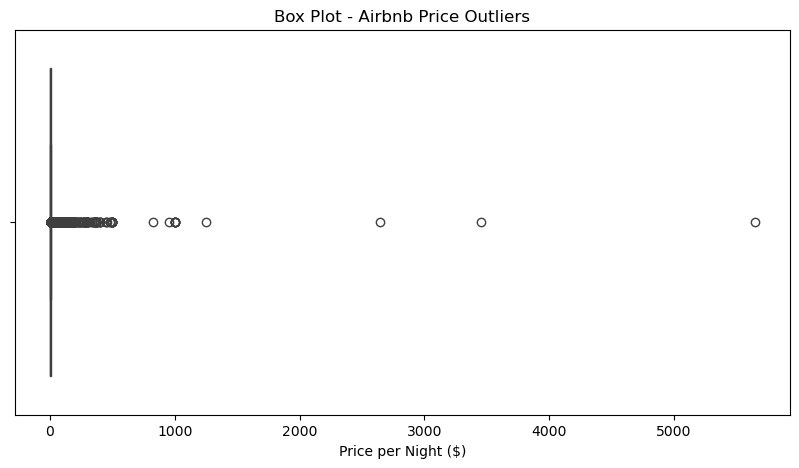

In [74]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=new_data_frame_to_clean["Minimum_Nights"])

plt.title("Box Plot - Airbnb Price Outliers")
plt.xlabel("Price per Night ($)")
plt.show()

In [73]:
columns_to_check = [
    "Price($)",
    "Service_Fees($)",
    "Minimum_Nights",
    "Number_of_Reviews",
    "Reviews_Per_Month",
    "Calculated_Host_Listings_Count"
]

# Detect outliers using IQR
for col in columns_to_check:
    new_data_frame_to_clean[col] = pd.to_numeric(new_data_frame_to_clean[col], errors="coerce")

    Q1 = new_data_frame_to_clean[col].quantile(0.25)
    Q3 = new_data_frame_to_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = new_data_frame_to_clean[
        (new_data_frame_to_clean[col] < lower_limit) |
        (new_data_frame_to_clean[col] > upper_limit)
    ]

    print(f"\nColumn: {col}")
    print("Lower limit:", lower_limit)
    print("Upper limit:", upper_limit)
    print("Outlier count:", len(outliers))


Column: Price($)
Lower limit: -515.5
Upper limit: 1768.5
Outlier count: 0

Column: Service_Fees($)
Lower limit: -104.5
Upper limit: 355.5
Outlier count: 0

Column: Minimum_Nights
Lower limit: -5.0
Upper limit: 11.0
Outlier count: 17256

Column: Number_of_Reviews
Lower limit: -42.5
Upper limit: 73.5
Outlier count: 11696

Column: Reviews_Per_Month
Lower limit: -2.34
Upper limit: 4.14
Outlier count: 5726

Column: Calculated_Host_Listings_Count
Lower limit: -0.5
Upper limit: 3.5
Outlier count: 17702
